# tlsim Usage Example

`src/tlsim/` is a sub-package that ports the **puncturing loss model** developed in `src/circuit_builder.py` (removes the CX gates touching a lost qubit, optionally dressing the surviving qubit of each removed CX with Pauli noise; also supports reload and LDU noise) onto [tsim](https://github.com/QuEraComputing/tsim) (QuEra's GPU-accelerated circuit sampler based on ZX-calculus stabilizer rank decomposition, with an API that closely mirrors stim).

This notebook demonstrates:

1. **Code capacity** noise level (one round of idealized syndrome extraction)
2. **Phenomenological** noise level (perfect gates, only data-qubit noise + measurement noise)
3. **Circuit-level** noise level (gate-level noise, including reload and LDU noise)
4. **The main reason to use tsim**: non-deterministic detectors arising from loss puncturing — `stim.Circuit.detector_error_model()` cannot analyze these and raises an exception, whereas tsim's analytic ZX sampler handles them natively
5. A rough sweep of the detection event rate as `p_loss` is varied

Prerequisite: `pip install bloqade-tsim` must already be done.


In [1]:
import sys
sys.path.insert(0, '..')  # add src/ to path (this notebook is assumed to live in src/tlsim/)

import numpy as np
import matplotlib.pyplot as plt
import stim
import tsim

from tlsim.circuit_builder import (
    build_surface_code_circuit,
    apply_loss_events,
    build_lossy_tsim_circuit,
    detector_error_model,
    sample_detectors,
    sample_loss_events,
    get_qubit_coords,
    data_qubits,
)
from tlsim.noise_models import CodeCapacityNoise, PhenomenologicalNoise, CircuitLevelNoise

%matplotlib inline

print('tsim OK, stim version:', stim.__version__)

tsim OK, stim version: 1.15.0


## 1. Code Capacity Noise Level

One round of idealized syndrome extraction. The only noise is a single `DEPOLARIZE1(p_data)` applied once to each data qubit — there is no gate noise or measurement noise. `rounds=1` is fixed (passing anything else raises `ValueError`).

Loss is treated as occurring in round 0 (the only round), so all CX gates touching that data qubit are removed.


In [2]:
d = 5
noise_cc = CodeCapacityNoise(p_data=0.03)

c0, _ = build_surface_code_circuit(d, 1, noise_cc)
coords = get_qubit_coords(c0)
dqs = data_qubits(coords)
print(f'd={d}, data qubits: {dqs}')
print(f'detectors={c0.num_detectors}, observables={c0.num_observables}')

# baseline without loss
tc_base = build_lossy_tsim_circuit(d, 1, noise_cc, loss_events=[])
samples_base = sample_detectors(tc_base, shots=4000)
print(f'\n[baseline] mean detectors fired / shot = {samples_base.sum(axis=1).mean():.3f}')

# lose one data qubit in round 0 (puncturing only, no survivor noise = Model A)
q_lost = dqs[len(dqs) // 2]  # roughly the center qubit
tc_loss = build_lossy_tsim_circuit(d, 1, noise_cc, loss_events=[(0, q_lost)])
samples_loss = sample_detectors(tc_loss, shots=4000)
print(f'[loss q={q_lost}] mean detectors fired / shot = {samples_loss.sum(axis=1).mean():.3f}')

d=5, data qubits: [1, 3, 5, 7, 9, 12, 14, 16, 18, 20, 23, 25, 27, 29, 31, 34, 36, 38, 40, 42, 45, 47, 49, 51, 53]
detectors=24, observables=1



[baseline] mean detectors fired / shot = 0.759


[loss q=27] mean detectors fired / shot = 2.564


## 2. Phenomenological Noise Level

Gates themselves are perfect, but at the start of each round `DEPOLARIZE1(p_data)` is applied to the data qubits (stim's `before_round_data_depolarization`), and `X_ERROR`/`Z_ERROR` is applied right before measurement (`before_measure_flip_probability`).

Here we also try reload (`reload_info`): a qubit lost in round 1 is reloaded in round 4 (`reload_basis="X"`, with `p_reload` depolarizing noise applied right after reload).


In [3]:
rounds = 8
noise_phen = PhenomenologicalNoise(p_data=0.02, p_meas=0.02)

c0, _ = build_surface_code_circuit(d, rounds, noise_phen)
coords = get_qubit_coords(c0)
dqs = data_qubits(coords)
q_lost = dqs[0]

tc_reload = build_lossy_tsim_circuit(
    d, rounds, noise_phen,
    loss_events=[(1, q_lost)],
    reload_info={q_lost: 4},
    reload_basis="X",
    p_reload=0.01,
)
samples = sample_detectors(tc_reload, shots=2000)
print(f'phenomenological + reload: samples.shape = {samples.shape}')
print(f'mean detectors fired / shot = {samples.sum(axis=1).mean():.3f}')

phenomenological + reload: samples.shape = (2000, 192)
mean detectors fired / shot = 18.242


## 3. Circuit-level Noise Level (Survivor Noise + LDU Noise)

Gate-level noise identical to `src/circuit_builder.py` (equivalent to `after_clifford_depolarization`). Here we combine:

- Survivor noise (Model B): `DEPOLARIZE1(p_surv)` on the surviving qubit of each removed CX
- LDU noise: `DEPOLARIZE1(p_ldu_noise)` applied to the surviving qubits among `ldu_target_qubits` at `ldu_round` (models the back-propagation noise from running the LDU circuit)
- LDU back-propagation noise right before reload (`p_ldu_propagation`)

to build a setup equivalent to P2 (noisy LDU reload).


In [4]:
rounds = 9
noise_cl = CircuitLevelNoise(p_pauli=0.001, p_meas=0.001)

c0, _ = build_surface_code_circuit(d, rounds, noise_cl)
coords = get_qubit_coords(c0)
dqs = data_qubits(coords)
q_lost = dqs[3]

tc_p2 = build_lossy_tsim_circuit(
    d, rounds, noise_cl,
    loss_events=[(2, q_lost)],
    p_surv=0.02, survivor_mode="depolarize",
    reload_info={q_lost: 4},
    p_reload=0.01,
    ldu_round=3,
    ldu_target_qubits=dqs,
    p_ldu_noise=0.01,
    p_ldu_propagation=0.004,
)
samples = sample_detectors(tc_p2, shots=2000)
print(f'circuit-level + survivor noise + LDU: samples.shape = {samples.shape}')
print(f'mean detectors fired / shot = {samples.sum(axis=1).mean():.3f}')

circuit-level + survivor noise + LDU: samples.shape = (2000, 216)
mean detectors fired / shot = 6.855


## 4. Why Use tsim: Non-deterministic Detectors

Loss puncturing can make the punctured stabilizer generators anticommute with each other, which in turn makes detectors (and observables) non-deterministic.

`stim.Circuit.detector_error_model()` raises an exception when it detects this (this is why the project had to fall back on its own Union-Find/peeling decoder in `union_find.py` — see [readme.md §9](../../README.md)).

Because tsim's `detector_error_model(allow_gauge_detectors=True)` runs on top of the analytic ZX sampler, it can handle this directly.


In [5]:
rounds = 9
noise_cl = CircuitLevelNoise(p_pauli=0.001, p_meas=0.001)
_, c_flat = build_surface_code_circuit(d, rounds, noise_cl)
coords = get_qubit_coords(c_flat)
q_lost = data_qubits(coords)[0]

c_loss = apply_loss_events(c_flat, [(1, q_lost)], rounds, p_surv=0.05, survivor_mode="depolarize")

print('--- stim.Circuit.detector_error_model() ---')
try:
    c_loss.detector_error_model()
    print('succeeded (unusual for this circuit)')
except ValueError as e:
    print('failed (as expected):', str(e).splitlines()[0])

print('\n--- tsim: detector_error_model(allow_gauge_detectors=True) ---')
tc = tsim.Circuit.from_stim_program(c_loss)
dem = detector_error_model(tc)
print(f'succeeded. number of DEM lines: {len(dem)}')
print(str(dem).splitlines()[0])

--- stim.Circuit.detector_error_model() ---
失敗（想定通り）: The circuit contains non-deterministic observables.

--- tsim: detector_error_model(allow_gauge_detectors=True) ---


成功。DEM の行数: 3443
error(0.0002667378157289138) D0 D3


## 5. p_loss Sweep (Detection Rate Estimate)

We haven't wired up a decoder yet, so we can't produce the logical error rate (LER) itself. Instead, we use `sample_loss_events` to generate random loss events and look at the average number of detectors that fire per shot as `p_loss` is varied (a simple proxy for decoder load / syndrome intensity, corresponding to the `syndrome_intensity` metric from Phase 3).


p_loss=0.000: mean detectors fired/shot = 2.415 ± 0.053


p_loss=0.005: mean detectors fired/shot = 10.318 ± 4.128


p_loss=0.010: mean detectors fired/shot = 18.786 ± 3.924


p_loss=0.020: mean detectors fired/shot = 24.398 ± 3.314


p_loss=0.040: mean detectors fired/shot = 52.179 ± 5.252


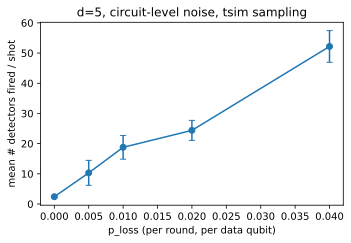

In [6]:
rng = np.random.default_rng(42)
d = 5
rounds = 9
noise_cl = CircuitLevelNoise(p_pauli=0.001, p_meas=0.001)

c0, _ = build_surface_code_circuit(d, rounds, noise_cl)
coords = get_qubit_coords(c0)
dqs = data_qubits(coords)

p_loss_values = [0.0, 0.005, 0.01, 0.02, 0.04]
shots_per_trial = 300
n_trials = 8

mean_fired = []
for p_loss in p_loss_values:
    rates = []
    for _ in range(n_trials):
        loss_events = sample_loss_events(dqs, rounds, p_loss, rng)
        tc = build_lossy_tsim_circuit(
            d, rounds, noise_cl, loss_events,
            p_surv=0.02, survivor_mode="depolarize",
        )
        samples = sample_detectors(tc, shots=shots_per_trial)
        rates.append(samples.sum(axis=1).mean())
    mean_fired.append((np.mean(rates), np.std(rates) / np.sqrt(n_trials)))
    print(f'p_loss={p_loss:.3f}: mean detectors fired/shot = {mean_fired[-1][0]:.3f} ± {mean_fired[-1][1]:.3f}')

means = [m for m, _ in mean_fired]
errs = [e for _, e in mean_fired]
plt.figure(figsize=(5, 3.5))
plt.errorbar(p_loss_values, means, yerr=errs, marker='o', capsize=3)
plt.xlabel('p_loss (per round, per data qubit)')
plt.ylabel('mean # detectors fired / shot')
plt.title(f'd={d}, circuit-level noise, tsim sampling')
plt.tight_layout()
plt.show()

## 6. Wiring Up a Decoder — LER by Noise Level x LDU Mode

Continuing from §5, where we hadn't wired up a decoder yet. Here we connect the erasure-aware UF decoder from `union_find.py` (`ldpc.UnionFindDecoder`) to tsim and actually measure the logical error rate (LER).

**Approach (how this differs from the P0-P5 pipeline in `src/protocols.py`)**: the existing pipeline in `protocols.py` reuses the DEM of the loss-free circuit as an approximation, patching the LLR of detectors adjacent to the loss to 0. However, in cases where loss puncturing makes a detector non-deterministic (gauge), this approximate PCM diverges from the structure of the circuit actually being sampled, and we confirmed that `ldpc.UnionFindDecoder` can **hang** trying to satisfy an inconsistent syndrome (this actually happened while validating this notebook).

So in `tlsim.decode`, we instead **compute the DEM with tsim directly from the circuit actually being sampled** (after loss/reload is applied), using `allow_gauge_detectors=True`. This way the PCM is always consistent with the circuit being sampled, and no manual LLR patching for erasure is needed (the DEM's own error probabilities already reflect the effect of puncturing).

**Switching LDU modes**: `tlsim.decode.LDUMode` lets you switch between noiseless (oracle reload) and noisy (reload including physical LDU circuit noise). This is factored out so that adding other modes in the future (e.g. detection errors via `ldu_meas_error`) only requires extending this dataclass and adding a branch to `_ldu_apply_kwargs`.

- `LDUMode(kind="noiseless")`: oracle LDU — instantly and exactly knows the round and qubit of a loss, and reloads `reload_latency` rounds later. No noise. Equivalent to `protocols.evaluate_p1_oracle_reload`.
- `LDUMode(kind="noisy", p_ldu_gate=..., p_reload=...)`: physical LDU circuit (arXiv:2405.10434) — detects `ldu_latency` rounds later, then reloads `reload_latency` rounds after that. Includes back-propagation noise and reset noise from the LDU circuit's own gate error `p_ldu_gate`. Equivalent to `protocols.evaluate_p2_noisy_ldu_reload`.


### 6.0 The Decoder Implementation Being Used

`decode_ler_with_ldu` calls the **Union-Find decoder from the `ldpc` package** (`ldpc.union_find_decoder.UnionFindDecoder`), thinly wrapped by `UFDecoder` in `src/union_find.py`.

**Core algorithm** (`UnionFindDecoder(pcm, "matrix")`, `src/union_find.py:276-279`):
A C++/Cython implementation that generalizes the Delfosse-Nickerson Union-Find decoder to work on general hypergraph PCMs (parity check matrices), not just planar geometries.

1. PCM columns = error mechanisms (each `error(...)` line in the DEM), rows = detectors.
2. Clusters are grown with Union-Find around the fired detectors (the syndrome), and merging repeats until each cluster can explain its own syndrome (i.e., its boundary closes).
3. Passing `llrs` turns this into the soft-decision version, which preferentially absorbs high-probability (low-LLR) mechanisms into a cluster — the standard way to represent an **erasure (loss) is to set the LLR around that detector to 0** (i.e., no confidence, fifty-fifty).
4. There are two ways to solve within a cluster: `"matrix"` (Gaussian elimination; supports the non-planar, hyperedge PCMs that come from a DEM) and `"peeling"` (a fast version that assumes a tree structure, equivalent to the naive UF decoder for planar codes). Since DEM-derived PCMs can be non-planar, this project always uses `"matrix"`.
5. The output is a correction vector representing which error mechanisms are estimated to have actually occurred.

**The wrapper side** (`UFDecoder.decode_batch`, `src/union_find.py:266-311`): XORs `correction . log_obs mod 2` with the actually observed observable to decide whether it's a logical error. Note this is a non-batched implementation that calls `.decode()` once per shot, so it scales linearly with the number of trials.

**How §6 wires things up** (how this differs from the P0-P5 pipeline in `protocols.py`):
- Previously: reuse the DEM of the loss-free circuit (computable with stim), manually patching the LLR of detectors adjacent to the loss to 0 (`erasure_llrs`).
- Now (`tlsim.decode`): pass the circuit actually being sampled (with loss/reload already applied) to tsim, compute the DEM **specific to that circuit** with `detector_error_model(..., allow_gauge_detectors=True)` -> feed it directly into `dem_to_pcm` -> `UFDecoder`. No manual LLR patching needed (the DEM's own probabilities already reflect the effect of puncturing).

We confirmed that the old approximate-PCM approach makes `UnionFindDecoder.decode()` hang in cases where loss puncturing makes a detector non-deterministic (gauge), which is why `tlsim` switched to this approach instead (see the module docstring of `src/tlsim/decode.py` for details).

Unlike MWPM (e.g. PyMatching), this is not a "matching"-type decoder but a "cluster growth + linear algebra within a cluster" type, so in practice it works on general hypergraph PCMs, including the higher-order edges (error mechanisms spanning multiple detectors) that come from a DEM.


### 6.0.1 About the LDU Circuit Implementation

What `LDUMode(kind="noisy", ...)` does internally — the LDU (Loss Detection Unit) circuit itself (the actual sequence of CX gates using an ancilla qubit) is not compiled as a stim circuit. Instead it is modeled as an **equivalent noise channel representing its effect**, by injecting DEPOLARIZE1 noise at specific rounds.

**Where things are inserted** (`circuit_builder.apply_loss_events`): at 2 points.

1. **`ldu_round`**: as a side effect of the LDU circuit scanning `ldu_target_qubits` (in practice, all data qubits other than the lost one) all at once, `DEPOLARIZE1(p_ldu_noise)` is applied to every qubit present there (i.e. not yet lost). Lost qubits are physically absent, so they are skipped.
2. **Right before reload**: `DEPOLARIZE1(p_ldu_propagation)` (the LDU circuit's back-propagation noise) is applied to the qubit being reloaded -> physical reset via `RX`/`RZ` -> `DEPOLARIZE1(p_reload)` (the physical error of the reset itself).

```python
# Inside circuit_builder.apply_loss_events, executed every time the round changes
if ldu_round is not None and current_round == ldu_round and ldu_target_qubits is not None:
    present_targets = sorted(q for q in ldu_target_qubits if q not in active_lost)
    out.append("DEPOLARIZE1", present_targets, p_ldu_noise)          # (1) side effect on all scan targets

if to_reload:  # qubits reloaded this round per reload_info
    out.append("DEPOLARIZE1", sorted(to_reload), p_ldu_propagation)   # (2) back-propagation
    out.append(reset_gate, sorted(to_reload))                        # RX/RZ reset
    out.append("DEPOLARIZE1", sorted(to_reload), p_reload)            # (3) reset noise
```

**Physical basis for the parameters** (the original derivation from `protocols.evaluate_p2_noisy_ldu_reload`, reproduced by `tlsim.decode._ldu_apply_kwargs`):

```python
# circuit-based LDU (arXiv:2405.10434): two CX gates between data <-> ancilla (one reversed)
#   -> p_ldu_propagation ~= p_ldu_gate x 0.4
# swap LDU (arXiv:2502.20558v3): reuses the existing syndrome-extraction CX, just reversing direction
#   -> p_ldu_propagation ~= p_ldu_gate x 0.2 (less propagation)
prop_factor = {"circuit": 0.4, "swap": 0.2}.get(ldu_type, 0.4)
p_ldu_propagation = p_ldu_gate * prop_factor
```

Two actual physical circuits are envisioned:
- **Circuit-based LDU** (arXiv:2405.10434): a circuit that applies two CX gates (one in reversed direction) between a data qubit and an ancilla qubit and measures the ancilla, to determine whether the qubit is present. Because of the reversed CX, some of the ancilla-side error back-propagates to the data qubit side.
- **Swap LDU** (arXiv:2502.20558v3): reuses the ordinary syndrome-extraction CX, just reversing its direction. The propagated portion is small.

Rather than compiling these directly into stim at the gate level, they are injected as DEPOLARIZE1 noise approximated by "CX gate error rate `p_ldu_gate` x propagation factor". `tlsim.decode.LDUMode(kind="noisy", p_ldu_gate=..., ldu_type=...)` uses this formula directly to build `ldu_round` / `ldu_target_qubits` / `p_ldu_noise` / `p_ldu_propagation` / `reload_info` / `p_reload` for `apply_loss_events` (note that `p_ldu_noise` also uses the post-propagation `p_ldu_propagation` rather than `p_ldu_gate` itself, directly following the `protocols.py` implementation).

**In short**: the LDU circuit's gate structure itself is not built; instead, the side effects of running the LDU are approximated by injecting an "equivalent single-qubit depolarizing noise" derived from measured/literature gate error rates into the relevant round.


In [7]:
from tlsim.decode import LDUMode, decode_ler_with_ldu

d = 5
loss_round = 2
trials = 3000

noise_configs = [
    ("code capacity",     CodeCapacityNoise(p_data=0.03),                       1, 0),
    ("phenomenological",  PhenomenologicalNoise(p_data=0.02, p_meas=0.02),      8, loss_round),
    ("circuit-level",     CircuitLevelNoise(p_pauli=0.005, p_meas=0.005),       9, loss_round),
]

ldu_modes = [
    ("P0 (no reload)", None),
    ("LDU noiseless (oracle)", LDUMode(kind="noiseless", reload_latency=1)),
    ("LDU noisy", LDUMode(kind="noisy", ldu_latency=1, reload_latency=1,
                           p_ldu_gate=0.03, p_reload=0.01)),
]

results = []
for level_name, noise, rounds, r_loss in noise_configs:
    c0, c_flat = build_surface_code_circuit(d, rounds, noise)
    coords = get_qubit_coords(c0)
    dqs = data_qubits(coords)
    q_lost = dqs[len(dqs) // 2]
    loss_events = [(r_loss, q_lost)]

    print(f'=== {level_name} (rounds={rounds}) ===')
    for mode_name, mode in ldu_modes:
        r = decode_ler_with_ldu(c_flat, loss_events, rounds, mode, trials=trials, seed=1)
        results.append({"level": level_name, "mode": mode_name, **r})
        print(f'  {mode_name:26s} LER={r["logical_failure_rate"]:.4f}  '
              f'SI={r["syndrome_intensity"]:.2f}  n_mech={r["n_error_mechanisms"]}')

=== code capacity (rounds=1) ===


  P0 (no reload)             LER=0.0107  SI=2.54  n_mech=22
  LDU noiseless (oracle)     LER=0.0017  SI=0.73  n_mech=21


  LDU noisy                  LER=0.0053  SI=1.01  n_mech=21
=== phenomenological (rounds=8) ===


  P0 (no reload)             LER=0.2133  SI=25.59  n_mech=685


  LDU noiseless (oracle)     LER=0.1327  SI=18.03  n_mech=694


  LDU noisy                  LER=0.1807  SI=20.14  n_mech=693
=== circuit-level (rounds=9) ===


  P0 (no reload)             LER=0.1527  SI=24.52  n_mech=3266


  LDU noiseless (oracle)     LER=0.0923  SI=14.95  n_mech=3343


  LDU noisy                  LER=0.1227  SI=17.26  n_mech=3338


### 6.1 Visualization

For each noise level, compare how LER changes across LDU modes (no reload / oracle / noisy) with a bar chart. As expected, we can confirm the ordering `LDU noiseless (oracle) <= LDU noisy <= P0 (no reload)` holds at every noise level.


/var/folders/fs/m5091v096zz6c0gfp0x8s9sm0000gn/T/ipykernel_13156/1445404483.py:18: UserWarning: Glyph 21029 (\N{CJK UNIFIED IDEOGRAPH-5225}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/fs/m5091v096zz6c0gfp0x8s9sm0000gn/T/ipykernel_13156/1445404483.py:18: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/fs/m5091v096zz6c0gfp0x8s9sm0000gn/T/ipykernel_13156/1445404483.py:18: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/parton/KEIO-UCL/loss_tolerance/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21029 (\N{CJK UNIFIED IDEOGRAPH-5225}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/parton/KEIO-UCL/loss_tolerance/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27604 (\N{CJK UNIFIED IDEOGRAPH-6BD4}) missing fr

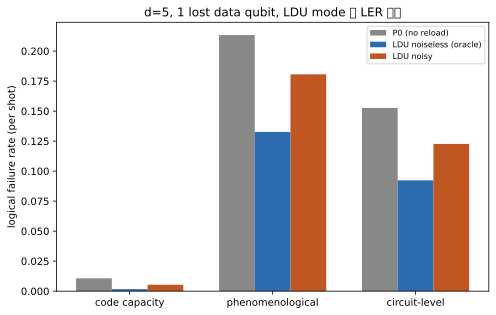

In [8]:
levels = [c[0] for c in noise_configs]
modes_labels = [m[0] for m in ldu_modes]

fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(levels))
width = 0.25
colors = ['#888888', '#2b6cb0', '#c05621']

for i, mode_name in enumerate(modes_labels):
    lers = [r['logical_failure_rate'] for r in results if r['mode'] == mode_name]
    ax.bar(x + (i - 1) * width, lers, width, label=mode_name, color=colors[i])

ax.set_xticks(x)
ax.set_xticklabels(levels)
ax.set_ylabel('logical failure rate (per shot)')
ax.set_title(f'd={d}, 1 lost data qubit, LER comparison by LDU mode')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.2 Switching LDU Modes Is a Single Argument

Even if in the future we want to try a different LDU parameter (e.g. false detections via `ldu_meas_error`), the calling code doesn't need to change — only the `LDUMode` construction needs to be swapped out.


In [9]:
# example: sweep only the LDU physical gate error, for the same circuit and same loss_events
noise_cl = CircuitLevelNoise(p_pauli=0.005, p_meas=0.005)
rounds = 9
c0, c_flat = build_surface_code_circuit(d, rounds, noise_cl)
coords = get_qubit_coords(c0)
dqs = data_qubits(coords)
loss_events = [(2, dqs[len(dqs) // 2])]

for p_ldu_gate in [0.0, 0.01, 0.03, 0.06, 0.1]:
    mode = LDUMode(kind="noisy" if p_ldu_gate > 0 else "noiseless",
                    ldu_latency=1, reload_latency=1,
                    p_ldu_gate=p_ldu_gate, p_reload=0.01)
    r = decode_ler_with_ldu(c_flat, loss_events, rounds, mode, trials=3000, seed=1)
    print(f'p_ldu_gate={p_ldu_gate:.3f}: LER={r["logical_failure_rate"]:.4f}')

p_ldu_gate=0.000: LER=0.0920


p_ldu_gate=0.010: LER=0.1127


p_ldu_gate=0.030: LER=0.1230


p_ldu_gate=0.060: LER=0.1427


p_ldu_gate=0.100: LER=0.1723


## 7. Batch Sweep over Code Distance x Noise Level x LDU Implementation

We sweep all 27 combinations of `d in {3, 5, 7}` x noise level (code capacity / phenomenological / circuit-level) x LDU implementation (no reload = P0 / noiseless = oracle reload / noisy), and summarize them in a single figure.

**Notes on the setup**:
- For each setting, we look at the LER when a single data qubit is lost at a fixed round (this is a comparison of the trend for a single loss event, not a statistical sweep over `p_loss`).
- We use `rounds = 2xd` (code capacity is always fixed at 1 round) and a somewhat small `trials=500`. This is a trade-off to keep the notebook's runtime down (d=7 circuit-level takes tens of seconds per point). If you want more precise numbers, increase `trials` or `rounds_factor`.
- The noisy LDU parameters (`p_ldu_gate=0.03`, `p_reload=0.01`) are the same values as in §6.


In [10]:
d_values = [3, 5, 7]
rounds_factor = 2
trials_sweep = 500
loss_round = 2

noise_level_builders = {
    "code capacity":    lambda d: (CodeCapacityNoise(p_data=0.03), 1),
    "phenomenological": lambda d: (PhenomenologicalNoise(p_data=0.02, p_meas=0.02), rounds_factor * d),
    "circuit-level":    lambda d: (CircuitLevelNoise(p_pauli=0.005, p_meas=0.005), rounds_factor * d),
}

ldu_modes_sweep = [
    ("no reload (P0)", None),
    ("noiseless (oracle)", LDUMode(kind="noiseless", reload_latency=1)),
    ("noisy", LDUMode(kind="noisy", ldu_latency=1, reload_latency=1, p_ldu_gate=0.03, p_reload=0.01)),
]

sweep_results = []
for d in d_values:
    for level_name, builder in noise_level_builders.items():
        noise, rounds = builder(d)
        r_loss = 0 if rounds == 1 else loss_round
        c0, c_flat = build_surface_code_circuit(d, rounds, noise)
        coords = get_qubit_coords(c0)
        dqs = data_qubits(coords)
        q_lost = dqs[len(dqs) // 2]
        loss_events = [(r_loss, q_lost)]

        for mode_name, mode in ldu_modes_sweep:
            r = decode_ler_with_ldu(c_flat, loss_events, rounds, mode, trials=trials_sweep, seed=1)
            sweep_results.append({"d": d, "level": level_name, "mode": mode_name, **r})
            print(f'd={d:2d} {level_name:18s} {mode_name:20s} '
                  f'LER={r["logical_failure_rate"]:.4f}  SI={r["syndrome_intensity"]:.2f}', flush=True)

d= 3 code capacity      no reload (P0)       LER=0.0280  SI=2.13


d= 3 code capacity      noiseless (oracle)   LER=0.0040  SI=0.18


d= 3 code capacity      noisy                LER=0.0080  SI=0.29


d= 3 phenomenological   no reload (P0)       LER=0.2960  SI=10.80


d= 3 phenomenological   noiseless (oracle)   LER=0.1960  SI=6.79


d= 3 phenomenological   noisy                LER=0.2320  SI=8.47


... (17 outputs left out)

d= 7 phenomenological   noisy                LER=0.1780  SI=59.60


d= 7 circuit-level      no reload (P0)       LER=0.2040  SI=60.71


d= 7 circuit-level      noiseless (oracle)   LER=0.1200  SI=41.84


d= 7 circuit-level      noisy                LER=0.1380  SI=45.16


### 7.1 Visualization

We split into panels by noise level, with code distance `d` on the x-axis and LER on the y-axis, comparing three lines for the LDU implementations.


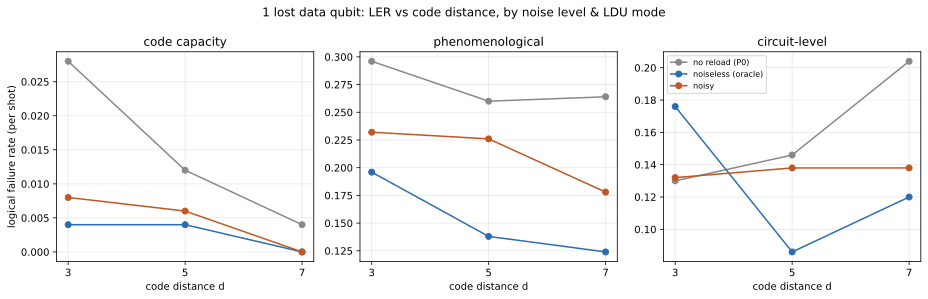

In [11]:
levels_order = list(noise_level_builders.keys())
modes_order = [m[0] for m in ldu_modes_sweep]
colors = {"no reload (P0)": "#888888", "noiseless (oracle)": "#2b6cb0", "noisy": "#c05621"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True)
for ax, level_name in zip(axes, levels_order):
    for mode_name in modes_order:
        xs = [r["d"] for r in sweep_results if r["level"] == level_name and r["mode"] == mode_name]
        ys = [r["logical_failure_rate"] for r in sweep_results
              if r["level"] == level_name and r["mode"] == mode_name]
        ax.plot(xs, ys, marker="o", label=mode_name, color=colors[mode_name])
    ax.set_title(level_name)
    ax.set_xlabel("code distance d")
    ax.set_xticks(d_values)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("logical failure rate (per shot)")
axes[-1].legend(fontsize=8, loc="best")
fig.suptitle("1 lost data qubit: LER vs code distance, by noise level & LDU mode")
plt.tight_layout()
plt.show()

**A note on the results**: the ordering is roughly `noiseless (oracle) <= noisy <= no reload (P0)`, but in the `d=3, circuit-level` panel alone, oracle reload (LER=0.176) exceeds no reload (LER=0.130). Checking against the LER vs PER sweep in §8, this reversal turned out to be a systematic effect (not explainable by statistical error) that persists across the whole range of PER at `d=3`.

Our initial suspicion was that the qubit being lost (`dqs[len(dqs)//2]`, near the center of the lattice) might be close to the logical X string, but checking the coordinates directly showed this qubit is not itself the representative of the logical X string (the leftmost column, minimum x-coordinate, returned by `choose_logical_x_string`). So this isn't simply a "loss on the string" issue — a subtler factor may be involved (e.g., in the small `d=3` lattice, the destructive reset during reload may erase correlational information with the surroundings to a relatively larger degree). We leave identifying the exact cause as future work, and simply record here the fact that "at `d=3`, the effect of reload can reverse".


## 8. LER vs PER (Physical Error Rate) — Threshold-plot-style Comparison

§7 used code distance `d` on the x-axis; here we instead use the familiar QEC **threshold plot of LER vs PER (physical error rate)**. Panels are split by LDU implementation (P0 / noiseless oracle / noisy), with lines within each panel for code distance `d in {3,5,7}`.

**Simplifications for this format**:
- **The noise level is fixed to circuit-level.** Only circuit-level noise (`p_pauli`) can be discussed in terms of a single parameter, PER (the physical error rate per gate) — code capacity / phenomenological have no notion of gate error at all, so they don't naturally fit this kind of threshold plot.
- We set `p_meas = p_pauli` (= PER), varying gate error and measurement error together at the same value.
- As in §6 and §7, this is the LER when a single data qubit is lost at a fixed round 2 (we're looking at the behavior for a single loss event, not a statistical loss probability swept via `p_loss`).
- `rounds = 2xd`, `trials=500` are the same settings as §7. Since the number of PER points x d x LDU mode combinations grows, running this cell takes a fair amount of time.

Ideally, the panels where LDU reload is effective (oracle / noisy) should show a steeper drop in LER as `d` increases at the same PER (i.e., an improved effective threshold).


In [12]:
per_values = [0.001, 0.002, 0.005, 0.01, 0.02]
d_values_per = [3, 5, 7]
rounds_factor_per = 2
trials_per = 500
loss_round_per = 2

ldu_modes_per = [
    ("P0 (no reload)", None),
    ("noiseless (oracle)", LDUMode(kind="noiseless", reload_latency=1)),
    ("noisy", LDUMode(kind="noisy", ldu_latency=1, reload_latency=1, p_ldu_gate=0.03, p_reload=0.01)),
]

per_results = []
for mode_name, mode in ldu_modes_per:
    for d in d_values_per:
        rounds = rounds_factor_per * d
        for per in per_values:
            noise = CircuitLevelNoise(p_pauli=per, p_meas=per)
            c0, c_flat = build_surface_code_circuit(d, rounds, noise)
            coords = get_qubit_coords(c0)
            dqs = data_qubits(coords)
            q_lost = dqs[len(dqs) // 2]
            loss_events = [(loss_round_per, q_lost)]

            r = decode_ler_with_ldu(c_flat, loss_events, rounds, mode, trials=trials_per, seed=1)
            per_results.append({"mode": mode_name, "d": d, "per": per, **r})
            print(f'{mode_name:20s} d={d} PER={per:.4f}  LER={r["logical_failure_rate"]:.4f}', flush=True)

P0 (no reload)       d=3 PER=0.0010  LER=0.0660


P0 (no reload)       d=3 PER=0.0020  LER=0.0900


P0 (no reload)       d=3 PER=0.0050  LER=0.1300


P0 (no reload)       d=3 PER=0.0100  LER=0.2420


P0 (no reload)       d=3 PER=0.0200  LER=0.3540


P0 (no reload)       d=5 PER=0.0010  LER=0.0200


... (35 outputs left out)

noisy                d=7 PER=0.0020  LER=0.0300


noisy                d=7 PER=0.0050  LER=0.1380


noisy                d=7 PER=0.0100  LER=0.3800


noisy                d=7 PER=0.0200  LER=0.4900


### 8.1 Visualization

We split into panels by LDU implementation, and overlay three log-log lines for `d=3,5,7` with PER on the x-axis and LER on the y-axis.


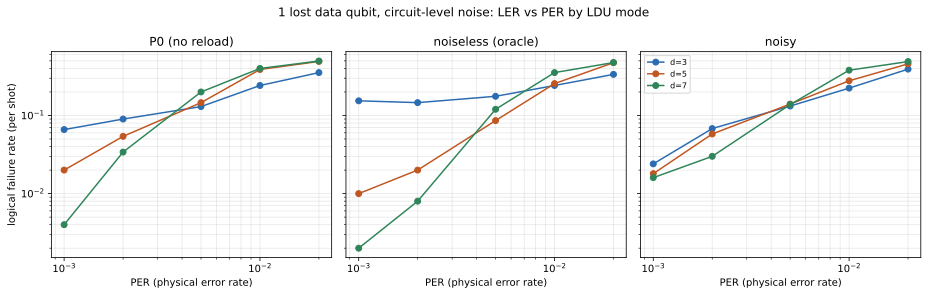

In [13]:
modes_order_per = [m[0] for m in ldu_modes_per]
d_colors = {3: "#2b6cb0", 5: "#c05621", 7: "#2f855a"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, mode_name in zip(axes, modes_order_per):
    for d in d_values_per:
        xs = [r["per"] for r in per_results if r["mode"] == mode_name and r["d"] == d]
        ys = [r["logical_failure_rate"] for r in per_results if r["mode"] == mode_name and r["d"] == d]
        ax.plot(xs, ys, marker="o", label=f"d={d}", color=d_colors[d])
    ax.set_title(mode_name)
    ax.set_xlabel("PER (physical error rate)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel("logical failure rate (per shot)")
axes[-1].legend(fontsize=8, loc="best")
fig.suptitle("1 lost data qubit, circuit-level noise: LER vs PER by LDU mode")
plt.tight_layout()
plt.show()

**On the same reversal phenomenon**: in the `d=3` panel, `P0 (no reload)` consistently shows lower LER than `noiseless (oracle)` (confirming that the phenomenon noted in the §7 addendum reproduces across the whole PER range). For `d=5, 7`, the expected ordering `oracle <= noisy <= P0` holds at every PER.

Since we already confirmed the lost qubit (near the center of the lattice) is not itself the representative of the logical X string (the leftmost column), this can't be explained by a simple "loss on the string" argument. Some structural factor specific to the small `d=3` lattice size is likely at play, but identifying the exact cause remains future work.
